# Notebook 05 - Chapter 4

Below you find exercises for Chapter 4. These exercises will prepare you in particular for the obligatory mid-term tests. The purpose of the prepared code snippets below is to give you some helpful structure for coding by predefining some useful variable names, but you do not need to use these prepared code snippets and prepared variable names if you do not want to. Do not hestitate to use the function `help()` to print the documentation of the functions that you need. If you are stuck, please ask one of the supervisors present.
<br>

Monte Carlo simulation is a flexible tool for pricing options with exotic payoffs including path-dependent options. It however tends to be rather inaccurate for a smaller number of simulations. Variance reduction techniques can help improve the accuracy of the method. In this tutorial we will use variance reduction techniques like the antithetic variables method, the control variates technique or importance sampling both in the Black&ndash;Scholes and in the Heston model. In order to price path-dependent options, we will employ both the Euler and Milshtein simulation scheme but also bias-free simulation methods.

In the code snippet below, we define the variables $r$, $\sigma$, $T$, $K$ and $S(0)$ for the Black&ndash;Scholes model and the variables $\gamma_0$, $\kappa$, $\lambda$ and $\widetilde \sigma$ for the Heston model.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm, norminvgauss
from scipy.optimize import minimize
print(os.getcwd())

r = 0.02
sigma = 0.3
gam0 = 0.3**2
kappa = 0.3**2
lamb = 2.5
sig_tilde = 0.3
T = 1
K = 100
S0 = 120

/home/jovyan/my_materials


After running the import-statements above there should be a line displayed with `'/home/jovyan/my_materials'.`

<br><br>

## Step 1: Pricing European options via Monte Carlo simulation with antithetic variables

The antithetic variables method is a simple approach for reducing the variance of a Monte Carlo estimator by doubling the number of considered paths in a special way. We will first start by computing a regular Monte Carlo estimator for the price of a European call option in the Black&ndash;Scholes model using $N = 10\,000$ simulations.

**Task 1.1**: Define $N = 10\,000$. Then, draw $N$ samples of the standard normal distribution and store them in an array `X`. Afterwards, compute the $N = 10\,000$ discounted payoffs \begin{equation} e^{-rT} \big( S(0) e^{(r - \sigma^2 / 2) T + \sigma \sqrt{T} X_n} - K\big)^+\end{equation}
and store them in an array `disc_payoffs`. Use the numpy random seed 20 for reproducibility.

*Useful Python commands*: `rng.normal`, `np.exp`, `np.maximum`, `np.sqrt`

In [2]:
N = 10000

rng = np.random.default_rng(seed=20)
X = rng.normal(loc=0, scale=1, size = N)
disc_payoffs = np.exp(-r * T) * np.maximum((S0 * np.exp((r - (sigma ** 2 * 0.5)) * T + sigma * np.sqrt(T) * X) - K), 0)

### Uncomment and execute the following line only if you obtained no result:
X1, disc_payoffs1 = np.loadtxt('../shared_materials/objects/5_1_1.txt')
print(np.array_equal(X, X1)) # True
print(np.array_equal(disc_payoffs, disc_payoffs1)) # True

True
True


**Task 1.2**: Use the array `disc_payoffs` to compute the Monte Carlo estimate $\widehat V_N$ for the European call option price $V(0)$ in the Black&ndash;Scholes model model and store it in a variable `call_BS_MC`. Then, define a variable `epsilon_95` that contains the half-width $\widehat \varepsilon_N := \smash{1.96 \sqrt{\frac{\widehat \sigma^2_N(f(X))}{N}}}$ of an approximate 95\% confidence interval for $V(0)$, where $\widehat \sigma^2_N(f(X))$ denotes the sample variance of the discounted payoffs from the array `disc_payoffs`. Then, print the variables `call_BS_MC` and `epsilon_95` as well as the relative percentage error $100\frac{\widehat \varepsilon_N}{\widehat V_N}$.

*Useful Python commands*: `np.mean`, `np.var` `np.sqrt`

In [3]:
call_BS_MC = np.mean(disc_payoffs)
epsilon_95 = 1.96 * np.sqrt(np.var(disc_payoffs, ddof = 1) / N)

print(call_BS_MC) # OK
print(epsilon_95) # OK

### Uncomment and execute the following line only if you obtained no result:
# call_BS_MC, epsilon_95 = 26.712204329439032, 0.6162434259408234

print('MC option price: {:.5f}, 95% error: {:.5f} ({:.5f}%)'.format(call_BS_MC, epsilon_95, 100 * epsilon_95 / call_BS_MC))

26.712204329439032
0.6162434259408234
MC option price: 26.71220, 95% error: 0.61624 (2.30697%)


We will now perform the antithetic variables method and will examine by how much the variance of the Monte Carlo estimator can be reduced by it.

**Task 1.3**: Define an array `disc_payoffs_anti` that contains the $N = 10\,000$ discounted payoffs $e^{-rT} (S(T) - K)^+$. Use the same formula as in Task 1.1 to compute the payoffs but instead of using the Gaussian simulations $X_n$, use the simulations $-X_n$. Then define an array `disc_payoffs_average` that contains the elementwise arithmetic average of the payoffs from `disc_payoffs` and `disc_payoffs_anti`.

*Useful Python commands*: `np.maximum`

In [4]:
disc_payoffs_anti = np.exp(-r * T) * np.maximum((S0 * np.exp((r - (sigma ** 2 * 0.5)) * T + sigma * np.sqrt(T) * -X) - K), 0)
disc_payoffs_average = 0.5 * (disc_payoffs + disc_payoffs_anti) # The elementwise arithmetic average
print(disc_payoffs_anti)
print(disc_payoffs_average)

### Uncomment and execute the following line only if you obtained no result:
disc_payoffs_anti1, disc_payoffs_average1 = np.loadtxt('../shared_materials/objects/5_1_3.txt')
print(disc_payoffs_anti1)
print(disc_payoffs_average1)
print(np.array_equal(disc_payoffs_anti, disc_payoffs_anti1)) # True
print(np.round(disc_payoffs_average, 10) == np.round(disc_payoffs_average1, 10)) # True

[29.77064228  0.          0.         ...  0.          0.
  0.        ]
[17.36829218 33.29632014 38.20756627 ... 29.21065638 23.54560257
 25.98367634]
[29.77064228  0.          0.         ...  0.          0.
  0.        ]
[17.36829218 33.29632014 38.20756627 ... 29.21065638 23.54560257
 25.98367634]
True
[ True  True  True ...  True  True  True]


**Task 1.4**: Repeat Task 1.2 but this time, use the array `disc_payoffs_average` instead of `disc_payoffs`. Store the resulting antithetic variables estimator and its 95% confidence interval half-width in variables `call_BS_MC_anti` and `epsilon_95_anti`. Again print them as well as the corresponding relative percentage error and interpret your result in comparison to the result from Task 1.2.

In [6]:
call_BS_MC_anti = np.mean(disc_payoffs_average)
epsilon_95_anti = 1.96 * np.sqrt(np.var(disc_payoffs_average, ddof = 1) / N)

print(call_BS_MC_anti) # OK
print(epsilon_95_anti) # OK

### Uncomment and execute the following line only if you obtained no result:
# call_BS_MC_anti, epsilon_95_anti = 26.804969427161105, 0.262186046349864

### call_BS_MC, epsilon_95 = 26.712204329439032, 0.6162434259408234  (quite different)

print('Antithetic MC option price: {:.4f}, 95% error: {:.4f} ({:.4f}%)'.format(call_BS_MC_anti, epsilon_95_anti, 100 * epsilon_95_anti / call_BS_MC_anti))

26.804969427161105
0.262186046349864
Antithetic MC option price: 26.8050, 95% error: 0.2622 (0.9781%)


We now want to visualize how much faster the antithetic variables Monte Carlo estimators converge to the true price of the European call option in the Black&ndash;Scholes model as the number $N$ of simulations grows. We first compute the true Black&ndash;Scholes price using the Black&ndash;Scholes formula.

**Task 1.5**: Copy your function `european_BS(t, St, K, T, r, sigma, call)` that computes European option prices in the Black&ndash;Scholes model from Task 1.5 of Notebook 02, or write it from scratch if you did not complete that task from week 03. Then, use this function to define a variable `call_BS` that contains the price $V(0)$ of the European call option with strike $K = 100$ and all other variables as set in the beginning of the notebook.

In [7]:
from scipy.stats import norm

def european_BS(t, St, K, T, r, sigma, call):

    d1 = (np.log(St/K) + (r + sigma ** 2 / 2) * (T - t)) / (sigma * np.sqrt(T - t))
    
    d2 = (np.log(St/K) + (r - sigma ** 2 / 2) * (T - t)) / (sigma * np.sqrt(T - t))

    # Put-Call-Parity
    if call == 1:
        return St * norm.cdf(d1) - K * np.exp(-r * (T - t)) * norm.cdf(d2)
        
    elif call == 0:
        return K * np.exp(-r * (T - t)) * norm.cdf(-d2) - St * norm.cdf(-d1)

call_BS = european_BS(0, S0, 100, T, r, sigma, call = 1)
print(call_BS) # OK

### Uncomment and execute the following line only if you obtained no result:
# call_BS = 26.803371450525006

26.803371450525006


**Task 1.6**: Define an array `call_BS_MC_path` of length $10\,000$. The $n$-th entry of this array should contain the Monte Carlo estimator for the European call option price using only the first $n$ simulations from the array `disc_payoffs`. Then, define an array `call_BS_MC_path_anti` of length $10\,000$. The $n$-th entry of this array should contain the antithetic variables Monte Carlo estimator for the European call option price using only the first $n$ simulations from the array `disc_payoffs_average`. 

*Useful Python commands*: `np.cumsum`

In [8]:
call_BS_MC_path = np.cumsum(disc_payoffs) / np.arange(1, N +1)
call_BS_MC_path_anti = np.cumsum(disc_payoffs_average) / np.arange(1, N + 1)

print(call_BS_MC_path)
print(call_BS_MC_path_anti)

### Uncomment and execute the following line only if you obtained no result:
call_BS_MC_path1, call_BS_MC_anti_path1 = np.loadtxt('../shared_materials/objects/5_1_6.txt')
print(np.array_equal(call_BS_MC_path, call_BS_MC_path1)) # True
print(np.array_equal(call_BS_MC_path_anti, call_BS_MC_anti_path1)) # True

[ 4.96594209 35.77929118 49.32457163 ... 26.70764    26.70967856
 26.71220433]
[17.36829218 25.33230616 29.62405953 ... 26.80537757 26.80505156
 26.80496943]
True
True


**Task 1.7**: Plot the Monte Carlo estimators from the array `call_BS_MC_path` against the number $n$ of simulations, starting from $n = 100$. In the same plot window, plot the antithetic variables Monte Carlo estimators from the array `call_BS_MC_path_anti` against the number $n$ of simulations, starting from $n = 100$. Draw a horizontal line at the height of the true option price stored in the variable `call_BS`. Interpret your result using a comment.

*Useful Python commands*: `plt.axhline`

<details>
  <summary>Result:</summary>

> <img src="../shared_materials/images/5_1_7.png" width="550"><details>
  <summary>Interpretation:</summary> It is clearly visible from the figure that the antithetic variables estimators (the orange line) converge much faster to the true price as the plain Monte Carlo estimators (the blue line) as the number $N$ of simulations is increased, which is due to the variance reduction introduced by the antithetic variables method.

 </details>
</details>

10000


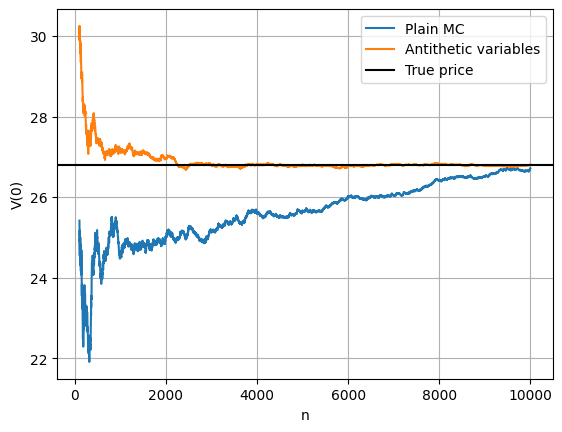

In [10]:
plt.plot(np.arange(100, N), call_BS_MC_path[100:], label = 'Plain MC')
plt.plot(np.arange(100, N), call_BS_MC_path_anti[100:], label = 'Antithetic variables') # Why not N + 1?
plt.axhline(call_BS, color = 'black', label = 'True price')
plt.xlabel('n')
plt.ylabel('V(0)')
plt.legend()
plt.grid()
print(N)

plt.show()

# Interpretation: It is clearly visible from the figure that the antithetic variables estimators (the orange line) 
# converge much faster to the true price as the plain Monte Carlo estimators (the blue line) as the number 
# of simulations is increased, which is due to the variance reduction introduced by the antithetic variables method.

<br>

## Step 2: Simulation of a geometric Brownian motion via the Euler and Milshtein schemes

For the valuation of path-dependent options it is necessary to simulate not only the terminal value $S(T)$ of the stock price path (as it was done in Step 1) but to simulate the whole path of the stock price $S(t)$, $t \in [0, T]$. Classical simulation schemes for stochastic integrals like the Euler scheme will sample $N$ discretized paths $S(t_0), S(t_1), \dots, S(t_m)$ with $0 = t_0 < t_1 < \dots < t_m = T$.

**Task 2.1**: Let $N = 10\,000$ and let $m = 1000$ be the number of steps per path, i.e. $\Delta T = T / m = T / 1000$. Initialize an array `dWt` of shape `(N, m)` for the increments of the Brownian motions $W$ containing independent normal random variables with mean 0 and standard deviation $\sqrt{\Delta t}$. Use the numpy random seed 20 to ensure reproducibility of your results.

*Useful Python commands*: `rng.normal`

In [11]:
N = 10000
m = 1000
dt = T / m

rng = np.random.default_rng(seed=20)
dWt = rng.normal(0, np.sqrt(dt), (N, m))
print(dWt)
print(np.shape(dWt))

### Uncomment and execute the following line only if you obtained no result:
dWt1 = np.loadtxt('../shared_materials/objects/5_2_1.txt')
print(np.array_equal(dWt, dWt1)) # True

[[-0.01137372  0.03806355  0.04417285 ...  0.00950927  0.0178238
  -0.00449554]
 [ 0.00841641  0.02018243  0.0140203  ...  0.03296518 -0.00282144
   0.01529469]
 [ 0.02576237 -0.06245736 -0.0049955  ...  0.02482989  0.00714792
  -0.01480114]
 ...
 [ 0.01885731  0.00131198 -0.04055355 ...  0.00591639  0.05610788
   0.02602853]
 [-0.02934413 -0.03174904  0.00826168 ...  0.02013086 -0.01422903
   0.01800005]
 [-0.05773302 -0.02814739  0.00311147 ... -0.02612058 -0.00034466
  -0.01671013]]
(10000, 1000)
True


**Task 2.2**: Initialize an array `S_Euler` of shape `(N, m + 1)` containing only zeros, which are later supposed to be filled with the $S$ paths. Set the elements of the first column of `S` equal to `S0`.

*Useful Python commands*: `np.zeros`

In [12]:
S_Euler = np.zeros((N, m +1)) # m = 1000
print(np.shape(S_Euler))
S_Euler[:, 0] = S0
print(S_Euler)

### Uncomment and execute the following line only if you obtained no result:
S_Euler1 = np.loadtxt('../shared_materials/objects/5_2_2.txt')
print(np.array_equal(S_Euler, S_Euler1)) # True

(10000, 1001)
[[120.   0.   0. ...   0.   0.   0.]
 [120.   0.   0. ...   0.   0.   0.]
 [120.   0.   0. ...   0.   0.   0.]
 ...
 [120.   0.   0. ...   0.   0.   0.]
 [120.   0.   0. ...   0.   0.   0.]
 [120.   0.   0. ...   0.   0.   0.]]
True


**Task 2.3**: Use a for-loop over the columns of `S` to compute the paths of the stock $S$ using the Euler method.

*Useful Python commands*: `np.sqrt`

In [13]:
# for i in range(m):
#    S_Euler[:, i + 1] = S_Euler[:, i] + r * S_Euler[:, i] * dt + sigma * S_Euler[:, i] * dWt[:, i]

for i in range(1, m + 1):
    S_Euler[:, i] = S_Euler[:, i - 1] + r * S_Euler[:, i - 1] * dt + sigma * S_Euler[:, i - 1] * dWt[:, i - 1]

print(S_Euler)
print(np.shape(S_Euler))

### Uncomment and execute the following line only if you obtained no result:
S_Euler1 = np.loadtxt('../shared_materials/objects/5_2_3.txt')
print(np.array_equal(S_Euler, S_Euler1)) # True

[[120.         119.59294625 120.9609777  ...  50.0653973   50.33410533
   50.26722831]
 [120.         120.3053908  121.03621347 ...  75.61782522  75.55533229
   75.90352191]
 [120.         120.92984527 118.66637605 ...  82.38359226  82.56190144
   82.1969495 ]
 ...
 [120.         120.68126315 120.73117624 ... 282.56388701 287.32575691
  289.57510386]
 [120.         118.94601116 117.81546373 ... 140.47649251 139.87964888
  140.63779868]
 [120.         117.92401128 116.93059399 ... 191.07549851 191.05956312
  190.10559504]]
(10000, 1001)
True


After having simulated stock price paths using the Euler method, we want to use the more refined Milshtein method, which has a smaller discretization bias, to simulate another set of stock price paths. 

**Task 2.4**: Repeat tasks 2.2 and 2.3 but this time, use the Milshtein scheme to simulate the stock price paths. To make the simulated paths comparable to those from Task 2.3, use the same simulations for the Brownian motion increments (stored in the array `dWt`) as used for the Euler method. Store your paths in an array `S_Milshtein` of shape `(N, m + 1)`.

In [14]:
S_Milshtein = np.zeros((N, m + 1))
S_Milshtein[:, 0] = S0


#for i in range(m):
#    S_Milshtein[:, i + 1] = S_Milshtein[:, i] + r * S_Milshtein[:, i] * dt + sigma * S_Milshtein[:, i] * dWt[:, i] + 0.5 * sigma ** 2 * S_Milshtein[:, i] * (dWt[:, i] ** 2 - dt)

for i in range(1, m + 1):
    S_Milshtein[:, i] = S_Milshtein[:, i - 1] + r * S_Milshtein[:, i - 1] * dt + sigma * S_Milshtein[:, i - 1] * dWt[:, i - 1] + 0.5 * sigma ** 2 * S_Milshtein[:, i - 1] * (dWt[:, i - 1] ** 2 - dt)


print(np.shape(S_Milshtein))

### Uncomment and execute the following line only if you obtained no result:
S_Milshtein1 = np.loadtxt('../shared_materials/objects/5_2_4.txt')
print(S_Milshtein1)
print(np.array_equal(S_Milshtein, S_Milshtein1)) # True

(10000, 1001)
[[120.         119.5882448  120.95863785 ...  50.18259287  50.4503891
   50.38113319]
 [120.         120.30037331 121.02795708 ...  75.64453417  75.57864226
   75.92433386]
 [120.         120.92802925 118.68038014 ...  82.23733598  82.411817
   82.0446324 ]
 ...
 [120.         120.67778338 120.72227388 ... 282.61482337 287.40487042
  289.65066555]
 [120.         118.94526098 117.81476351 ... 141.00260443 140.39846506
  141.15515593]
 [120.         117.93661003 116.94198418 ... 190.52933244 190.50486979
  189.54749235]]
True


**Task 2.5**: Plot the first simulated path from the array `S_Euler` and from the `S_Milshtein` in a common plot. In a separate plot window, plot the relative difference between those two paths as a fraction of the Milshtein path values and interpret your result using a comment.

<details>
  <summary>Result:</summary>

> <img src="../shared_materials/images/5_2_5.png" width="1050"><details>
  <summary>Interpretation:</summary> The figure shows that the Euler and Milshtein scheme yield very similar simulation results if the same random variables are used during the simulation. This is due to the quite fine discretization of $\Delta t = \frac{1}{1000}$. The only advantage of the Milshtein scheme over the Euler scheme is that it reduces the bias of the simulation scheme. Since however, for $\Delta t = \frac{1}{1000}$ the simulation bias is already quite small for the Euler method, the improvement that the Milshtein method yields is rather negligible and stays below 0.3% of the simulated values (see right figure). The improvement of the Milshtein scheme over the Euler scheme would be greater if $\Delta t$ were chosen larger.

 </details>
</details>

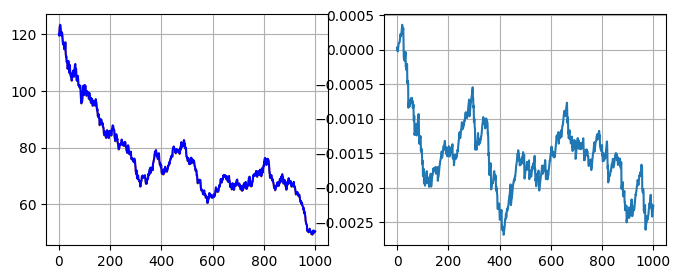

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(8, 3))
ax[0].plot(S_Euler[0, :], color = 'Orange')
ax[0].plot(S_Milshtein[0, :], color = 'blue')
ax[0].grid()
ax[1].plot((S_Euler[0, :] - S_Milshtein[0, :]) / S_Milshtein[0, :])
ax[1].grid()
plt.show()

# Interpretation: The figure shows that the Euler and Milshtein scheme yield very similar simulation results if the same random variables are used during the simulation. 
# This is due to the quite fine discretization of  dt. The only advantage of the Milshtein scheme over the Euler scheme is that it reduces the bias of the simulation scheme. Since however, for 
# dt = 1 / 1000. The simulation bias is already quite small for the Euler method, the improvement that the Milshtein method yields is rather negligible and stays below 0.3% of the simulated values 
# (see right figure). The improvement of the Milshtein scheme over the Euler scheme would be greater if dt were chosen larger.

<br>

## Step 3: Valuation of Parisian options using Monte Carlo estimation with control variates

A *cumulative Parisian option* is a variant of a Barrier option in which the barrier condition (i.e. the knock-in or the knock-out) only triggers if the barrier is surpassed cumulatively over a so-called trigger period of length $\tau > 0$. More precisely, we would like to compute the price of a *cumulative Parisian down-and-out call option* with strike $K = 100$, barrier $B = 110$ and trigger period 1 month (i.e. $\tau = \frac{1}{12})$. This means that the option pays out a payoff of $(S(T) - K)^+$ at the terminal time $T$ as long as the total cumulative time the stock price $S(t)$ has stayed below the barrier $B$ is smaller than $\tau$. This means that the payoff of this Parisian option is given by 
\begin{equation} V(T) = \begin{cases} (S(T) - K)^+ & \text{ if } \;\int_0^T 1_{\{S(t) < B\}} dt < \tau, \\ 0 & \text{ else.}
\end{cases}
\end{equation}

As simulated stock price paths, we want to use the $N = 10\,000$ simulations from the Milshtein scheme simulated in Task 2.4.

**Task 3.1**: Define variables `B` and `tau` for $B = 110$ and $\tau = \frac{1}{12}$. Then, initialize an array `disc_payoffs` of length $10\,000$ that contains the discounted payoffs $e^{-rT} V(T)$ of the parisian option for all $N = 10\,000$ paths from the array `S_Milshtein`. The condition $\int_0^T 1_{\{S(t) < B\}} dt < \tau$ means that less than $\tau\cdot m$ discretized points $S(t_i)$ are less than $B$.

*Useful Python commands*: `np.maximum`, `np.sum`

In [16]:
B = 110
tau = 1 / 12

print(np.shape(S_Milshtein))

condition = np.sum(S_Milshtein < B, axis = 1) < (tau * m) 
# For each simulated path, check whether the stock price stays below the barrier for fewer than tau proportion of the total time steps.

print(np.sum(S_Milshtein < B, axis = 1)) # Total ada berapa S_Milshtein yang lebih kecil dari B per row (time scale).

print((tau * m)) # tau proportion of the total time steps (jumlah steps selama 1 bulan dalam satu tahun ato period)

print(condition) # Output True False

disc_payoffs = np.exp(-r * T) * np.maximum(S_Milshtein[:, -1] - K, 0) * condition # Kalo yang False kali 0, kalo yang True kali 1
print(disc_payoffs)

### Uncomment and execute the following line only if you obtained no result:
disc_payoffs1 = np.loadtxt('../shared_materials/objects/5_3_1.txt')
print(disc_payoffs1)
print(np.array_equal(disc_payoffs, disc_payoffs1))

(10000, 1001)
[965 825 580 ...   0   0 102]
83.33333333333333
[False False False ...  True  True False]
[  0.           0.           0.         ... 185.89533076  40.34022924
   0.        ]
[  0.           0.           0.         ... 185.89533076  40.34022924
   0.        ]
True


In [17]:
# The option pays off if:

# 1. The stock price ends above the strike price (K = 100) at maturity (T = 1 year).

# 2. The total time the stock spent below the barrier (B = 110) over the entire year is less than one month.


**Task 3.2**: Use the array `disc_payoffs` to compute the Monte Carlo estimate $\widehat V_N$ for the Parisian option price $V(0)$ in the Black&ndash;Scholes model model and store it in a variable `parisian_call_BS_MC`. Then, define a variable `var_MC` that contains the sample variance $\widehat \sigma^2_N(f(X))$ of the discounted payoffs from the array `disc_payoffs`. Finally, define a variable `epsilon_95` that contains the half-width $\widehat \varepsilon_N := \smash{1.96 \sqrt{\frac{\widehat \sigma^2_N(f(X))}{N}}}$ of an approximate 95\% confidence interval for $V(0)$. Print the variables `parisian_call_BS_MC` and `epsilon_95` as well as the relative percentage error $100\frac{\widehat \varepsilon_N}{\widehat V_N}$.

*Useful Python commands*: `np.mean`, `np.var` `np.sqrt`

In [18]:
parisian_call_BS_MC = np.mean(disc_payoffs)
var_MC = np.var(disc_payoffs, ddof = 1)
epsilon_95 = 1.96 * np.sqrt(var_MC / N)

print(parisian_call_BS_MC) # OK
print(var_MC) # OK
print(epsilon_95) # OK

### Uncomment and execute the following line only if you obtained no result:
# parisian_call_BS_MC, var_MC, epsilon_95 = 19.890093513510575, 1058.8134841794981, 0.637772520639135

print('MC Parisian call option price: {:.4f}, 95% error: {:.4f} ({:.4f}%)'.format(parisian_call_BS_MC, epsilon_95, 100 * epsilon_95 / parisian_call_BS_MC))

19.890093513510575
1058.8134841794981
0.637772520639135
MC Parisian call option price: 19.8901, 95% error: 0.6378 (3.2065%)


We now want to reduce the 95% confidence error by using the control variates technique. A suitable candidate for a control variate for a Parisian down-and-out call is a regular down-and-out call because prices of regular down-and-out call options with barrier $B$ are known in closed form in the Black&ndash;Scholes model to be given by
\begin{equation} V_B(0) = S(0) \Big[\Phi(d_1) - \Big(\frac{B}{S(0)}\Big)^{\frac{2r}{\sigma^2} + 1} \Phi(m_1) \Big] - Ke^{-rT}  \Big[\Phi(d_2) - \Big(\frac{B}{S(0)}\Big)^{\frac{2r}{\sigma^2} - 1} \Phi(m_2) \Big]\end{equation}
with $d_1$ and $d_2$ as in (2.23) of the lecture notes and $m_1 = \frac{\log\big(\frac{B^2}{KS(0)}\big) + rT + \frac{\sigma^2}{2}T}{\sigma \sqrt{T}}$ and $m_2 = m_1 - \sigma \sqrt{T}$.

The code snippet below computes the time 0 price of a down-and-out call option with all parameters equal to those of the Parisian call option above.

In [19]:
# To reduce the uncertainty (variance), we use a technique called Control Variates.

# The Core Idea: We can use the price of a similar but simpler option that we know the exact true price for to "correct" 
# our estimate of the complicated one

In [20]:
d1 = (np.log(S0 / K) + r * T + sigma**2 / 2 * T) / (sigma * np.sqrt(T))
d2 = (np.log(S0 / K) + r * T - sigma**2 / 2 * T) / (sigma * np.sqrt(T))
m1 = (np.log(B**2 / (K * S0)) + r * T + sigma**2 / 2 * T) / (sigma * np.sqrt(T))
m2 = (np.log(B**2 / (K * S0)) + r * T - sigma**2 / 2 * T) / (sigma * np.sqrt(T))
barrier_call_BS = S0 * (norm.cdf(d1) - (B / S0)**(1 + 2 * r / sigma**2) * norm.cdf(m1)) - K * np.exp(-r * T) * (norm.cdf(d2) - (B / S0)**(2 * r / sigma**2 - 1) * norm.cdf(m2))
print('Down-and-out call option price: {:.4f}'.format(barrier_call_BS))

Down-and-out call option price: 12.8297


To compute the control variates estimate for the Parisian option, we first have to find the Monte Carlo estimate for the regular barrier option.

**Task 3.3**: Define an array `disc_barrier_payoffs` that contains the $N = 10\,000$ discounted payoffs $e^{-rT}\big(S(T) - K\big)^+ 1_{\{\min_{i} S(t_i) \geq B\}}$ for $K = 100$ for all the simulated Milshtein paths from Step 1. Use the array `disc_barrier_payoffs` to compute the Monte Carlo estimate $\widehat V_N$ for the regular down-and-out call option price $V(0)$ in the Black&ndash;Scholes model and store it in a variable `barrier_call_BS_MC`.

*Useful Python commands*: `np.maximum`, `np.mean`, `np.exp`, `np.min`

In [21]:
disc_barrier_payoffs = np.exp(-r * T) * np.maximum(S_Milshtein[:, -1] - K, 0) * (np.min(S_Milshtein, axis = 1) >= B)
# finds the minimum stock price reached along each individual path (across all 1000 time steps), see whether it is always >= B or not
# axis=1 (look across the columns (time steps) for each row (path)).
# all three parts must be true (or have a positive value) for a given simulated path
barrier_call_BS_MC = np.mean(disc_barrier_payoffs)

print(disc_barrier_payoffs)
print(barrier_call_BS_MC)

### Uncomment and execute the following line only if you obtained no result:
disc_barrier_payoffs1, barrier_call_BS_MC1 = np.loadtxt('../shared_materials/objects/5_3_3.txt'), 13.494702929075578
print(np.array_equal(disc_barrier_payoffs1, disc_barrier_payoffs)) # True

[  0.           0.           0.         ... 185.89533076  40.34022924
   0.        ]
13.494702929075578
True


**Task 3.4**: Compute the optimal value $\beta$ from equation (4.8) in the lecture notes. In our case, $f(X)$ stands for the discounted Parisian payoffs and $Y$ stands for the discounted payoffs of the regular down-and-out call in (4.8). Then, compute the control variates estimate $\widehat V^{CV}_N$ for the Parisian option and store it in a variable `parisian_call_BS_MC_CV`.

*Useful Python commands*: `np.var`. The sample covariance between to arrays `arr1` and `arr2` can be computed as `np.cov(arr1, arr2, ddof=1)[0, 1]`.

In [25]:
beta = np.cov(disc_payoffs, disc_barrier_payoffs, ddof = 1) [0, 1] / np.var(disc_barrier_payoffs, ddof = 1)
# parisian_call_BS_MC_CV = np.mean(disc_payoffs - disc_barrier_payoffs) + np.mean(disc_barrier_payoffs)

parisian_call_BS_MC_CV = parisian_call_BS_MC - beta * (barrier_call_BS_MC - barrier_call_BS)

print(beta) # OK
# print(parisian_call_BS_MC_CV)
print(parisian_call_BS_MC_CV) # OK

### Uncomment and execute the following line only if you obtained no result:
# beta, parisian_call_BS_MC_CV = 0.9026922816236712, 19.289845201882578

0.9026922816236712
19.28984520188258


As detailed on page 56 of the lecture notes, the variance `var_MC` from Task 2.2 is reduced by $\mathrm{Cov}(f(X), Y)^2 / \mathrm{Var}(Y)$ by using the optimal control variates estimate.

**Task 3.5**: Define a variable `epsilon_95_CV` that contains the half-width $\widehat \varepsilon^{CV}_N$ of an approximate 95\% confidence interval for $\widehat V^{CV}_N$. Print the variables `parisian_call_BS_MC_CV` and `epsilon_95_CV` as well as the relative percentage error $100\frac{\widehat \varepsilon_N^{CV}}{\widehat V^{CV}_N}$ and interpret your result in comparison to the result from Task 3.2.

*Useful Python commands*: `np.cov`, `np.var`, `np.sqrt`

<details>
  <summary>Interpretation:</summary>
    
> Compared to the plain Monte Carlo estimate without variance reduction, the 95% confidence interval width could be reduced by a factor of almost 2 from about 3.2065% to about 1.8626% of the price estimate, which originates from the control variates variance reduction. This shows that the ordinary barrier option is a very good proxy for the Parisian barrier option. 
</details>

In [27]:
var_MC_CV = (var_MC - (np.cov(disc_payoffs, disc_barrier_payoffs, ddof = 1) [0, 1]) ** 2 / np.var(disc_barrier_payoffs, ddof = 1)) / (4 * N)
epsilon_95_CV = 1.96 * np.sqrt(var_MC_CV)

print(var_MC_CV)
print(epsilon_95_CV)

# 0.03360336918589494

### Uncomment and execute the following line only if you obtained no result:
# var_MC_CV, epsilon_95_CV = 0.03360336918589494, 0.3592919468406354

print('MC Parisian call option price with CV: {:.4f}, 95% error: {:.4f} ({:.4f}%)'.format(parisian_call_BS_MC_CV, epsilon_95_CV, 100 * epsilon_95_CV / parisian_call_BS_MC_CV))

# Interpretation: ...

0.008400842296473735
0.1796459734203177
MC Parisian call option price with CV: 19.2898, 95% error: 0.1796 (0.9313%)


In [28]:
# Corrected Price = (Our Parisian Price) - β * (Our Regular Option Price Estimate - The True Regular Option Price)

<br>

## Step 4: Computation of option prices using importance sampling with exponential tilting

Suppose that a trader wants to compute the prices of European call options $V(0) = E_Q(e^{-rT} (S(T) - K)^+)$ in the exponential NIG model in which $S(t) = S(0) e^{(r - \omega)t + X(t)}$ and $X(t)$ is a so-called NIG (normal-inverse Gaussian) process with parameters $\alpha, \beta, \delta, \mu \in \mathbb{R}$ with $|\beta| < \alpha$. This means that $X(t) \sim \mathrm{NIG}(\alpha, \beta, \delta t, \mu t)$, where $\mathrm{NIG}$ denotes the so-called [NIG distribution](https://en.wikipedia.org/wiki/Normal-inverse_Gaussian_distribution). The constant $\omega$ above is defined by \begin{equation} \omega := \mu + \delta\Big(\sqrt{\alpha^2 - \beta^2} - \sqrt{\alpha^2 - (\beta + 1)^2}\Big). \end{equation}
This exponential NIG model has the advantage that it models logarithmic returns using the NIG distribution, which has much heavier tails than the normal distribution that is used in the Black&ndash;Scholes model.

We now want to compute $V(0) = E_Q(e^{-rT} (S(T) - K)^+)$ using Monte Carlo simulation in the NIG model with $\alpha = 1$, $\beta = 0$, $\delta = 0.3$ and $\mu = 0$. The code snippet below draws $N$ simulations of the $\mathrm{NIG}(\alpha, \beta, \delta T, 0)$ distribution with $\alpha = 1$, $\beta = 0$ and $\delta = 0.3$ using the scipy.stats class `norminvgauss`. It uses the numpy random seed 10 for reproducibility. 

*Remark*: The scipy.stats class is only able to draw simulations from a $\mathrm{NIG}(a, b, 1, 0)$ distribution for some $a, b > 0$ via the command `norminvgauss(a=a, b=b).rvs(N)`. This is however not a problem since $\mathrm{NIG}(\alpha, \beta, \delta T, 0) = \delta T \cdot\mathrm{NIG}(\alpha \delta T, \beta \delta T, 1, 0)$. Hence, we are able to simulate from the desired $\mathrm{NIG}(\alpha, \beta, \delta T, 0)$ distribution by setting $a = \alpha \delta T$ and $b = \beta \delta T$ and calculating $\delta T \cdot X_n$, where $X_n \sim \mathrm{NIG}(a, b, 1, 0)$.

In [29]:
N = 10000
alpha = 1
beta = 0
delta = 0.3

rng = np.random.default_rng(seed=10)
X = delta * T * norminvgauss(a=alpha * delta * T, b=beta * delta * T).rvs(N, random_state=rng)

**Task 4.1**: Define a variable `omega` for the constant $\omega$ as specified above. Then, initialize an array `disc_payoffs` that contains the discounted call option payoffs $e^{-rT} \big( S(0) \exp((r - \omega)T + \delta T X_n) - K\big)^+$, where $\delta T X_n$ are the variables from the array `X`, as before.

*Useful Python commands*: `np.sqrt`, `np.maximum`, `np.exp`

In [30]:
omega = delta * ((np.sqrt(alpha ** 2 - beta ** 2)) - (np.sqrt(alpha ** 2 - ((beta + 1) ** 2))))
disc_payoffs = np.exp(-r * T) * np.maximum((S0 * np.exp((r - omega) * T + X)) - K, 0)

print(omega)
print(disc_payoffs)

### Uncomment and execute the following line only if you obtained no result:
omega1, disc_payoffs1 = 0.3, np.loadtxt('../shared_materials/objects/5_4_1.txt')
print(omega1)
print(disc_payoffs1)
print(np.round(disc_payoffs, 10) == np.round(disc_payoffs1, 10))

0.3
[0. 0. 0. ... 0. 0. 0.]
0.3
[0. 0. 0. ... 0. 0. 0.]
[ True  True  True ...  True  True  True]


**Task 4.2**: Use the array `disc_payoffs` to compute the Monte Carlo estimate $\widehat V_N$ for the European call option price $V(0)$ in the NIG model and store it in a variable `call_NIG_MC`. Then, define a variable `epsilon_95` that contains the half-width $\widehat \varepsilon_N := \smash{1.96 \sqrt{\frac{\widehat \sigma^2_N(f(X))}{N}}}$ of an approximate 95\% confidence interval for $V(0)$, where $\widehat \sigma^2_N(f(X))$ denotes the sample variance of the discounted payoffs from the array `disc_payoffs`. Then, print the variables `call_NIG_MC` and `epsilon_95` as well as the relative percentage error $100\frac{\widehat \varepsilon_N}{\widehat V_N}$.

*Useful Python commands*: `np.mean`, `np.var` `np.sqrt`

In [31]:
call_NIG_MC = np.mean(disc_payoffs)
epsilon_95 = 1.96 * np.sqrt(np.var(disc_payoffs, ddof = 1) / N)

print(call_NIG_MC) # OK
print(epsilon_95) # OK

### Uncomment and execute the following line only if you obtained no result:
# call_NIG_MC, epsilon_95 = 35.23406383009554, 11.09205698959317

print('MC option price: {:.5f}, 95% error: {:.5f} ({:.5f}%)'.format(call_NIG_MC, epsilon_95, 100 * epsilon_95 / call_NIG_MC))

35.23406383009554
11.09205698959317
MC option price: 35.23406, 95% error: 11.09206 (31.48106%)


In [32]:
# Instead of simulating from the original distribution (which gives mostly zero payoffs), we simulate from a different distribution 
# that makes the "important" events (the huge payoffs) happen more often. Then, we mathematically "correct" for this bias so our 
# final price estimate is still accurate, but with much less uncertainty.

The above relative percentage error for the NIG model option price is rather high. We now want to use importance sampling to reduce that error.

If one wants to approximate the expected value $E[f(X)]$ using Monte Carlo simulation but the $X$ is supported mostly in regions where $f$ is comparatively small or even zero, it can be of advantage to use the importance sampling method, which relies on the estimator $\smash{\widehat V^{IS}_N = \frac{1}{N}\sum_{n=1}^N f(Y_n) \frac{g(Y_n)}{h(Y_n)}}$. Here, $g$ is the pdf of $X$, $h$ is some auxiliary pdf and $Y_1, \dots, Y_N$ are simulations from the pdf $h$. In practice, it is sometimes not clear how to choose a suitable auxiliary pdf $h$. In this case, the so-called *exponential tilting* method (also known as *Esscher transform*) can be used, which parameterizes $h$ via $\smash{h(x) := g(x) \frac{e^{\theta x}}{E(e^{\theta X})}}$ with some parameter $\theta \in \mathbb{R}$. One can then try different choices of the auxiliary parameter $\theta$ to find the one that provides the best variance reduction. The advantage of this choice of $h$ is that the ratio $\smash{\frac{g(x)}{h(x)}}$ used in the importance sampling estimator takes the very simple form $\smash{\frac{g(x)}{h(x)} = \frac{E(e^{\theta X})}{e^{\theta x}}}$.

Now, using exponential tilting on the NIG distribution is fairly easy: If $g$ denotes the pdf of the $\mathrm{NIG}(a,b, c, d)$ distribution, then one can show that $\smash{h(x) := g(x) \frac{e^{\theta x}}{E(e^{\theta X})}}$ is the pdf of the $\mathrm{NIG}(a, b + \theta, c, d)$ distribution as long as $-a- b < \theta < a - b$. Moreover, the value $E(e^{\theta X})$ is given by $E(e^{\theta X}) = \exp\big(d \theta + c\big(\sqrt{a^2 - b^2} - \sqrt{a^2 - (b + \theta)^2}\big)\big)$ for $X \sim \mathrm{NIG}(a, b, c, d)$. In the code snippet above Task 4.1, we simulated random variables $X_n$ from the $\mathrm{NIG}(\alpha \delta T, \beta \delta T, 1, 0)$ distribution, so $g$ is the pdf of the $\mathrm{NIG}(\alpha \delta T, \beta \delta T, 1, 0)$ distribution in our setting. In other words, $a = \alpha \delta T$, $b = \beta \delta T$, $c = 1$ and $d = 0$ in the above notation.

**Task 4.3**: Set $\theta$ equal to 0.1 to test the exponential tilting importance sampling. Then draw $N = 10\,000$ samples from the $\mathrm{NIG}(\alpha \delta T, \beta \delta T + \theta, 1, 0)$ distribution and store them in an array `Y`. Use the numpy random seed 10 for reproducibility. Then define a variable `mgf` that contains the value $E(e^{\theta X})$ for $X \sim \mathrm{NIG}(\alpha \delta T, \beta \delta T, 1, 0)$.

*Useful Python commands*: `N` simulations of the $\mathrm{NIG}(a, b, 1, 0)$ distribution can be obtained by the scipy.stats command `norminvgauss(a=a, b=b).rvs(N, random_state=rng)`.

In [33]:
theta = 0.1
rng = np.random.default_rng(seed=10)
Y = norminvgauss(a=alpha * delta * T, b=beta * delta * T + theta).rvs(N, random_state=rng)
mgf = np.exp(0 * theta + 1 * (np.sqrt((alpha * delta * T) ** 2 - (beta * delta * T) ** 2) - np.sqrt((alpha * delta * T) ** 2 - (beta * delta * T + theta) ** 2)))

print(Y) # OK
print(mgf) # OK

### Uncomment and execute the following line only if you obtained no result:
Y1, mgf1 = np.loadtxt('../shared_materials/objects/5_4_3.txt'), 1.0173053191783668
print(np.array_equal(Y, Y1)) # True

[ 0.29274118 -1.19818378  0.47588045 ... -0.09392275 -0.65473651
 -0.09385887]
1.0173053191783668
True


**Task 4.4**: Initialize an array `disc_payoffs_IS` that contains the discounted importance sampling "payoffs" $e^{-rT - \theta Y_n}  E(e^{\theta X}) \big( S(0) \exp((r - \omega)T + \delta T Y_n) - K\big)^+$. Then, calculate the importance sampling estimator $\widehat V^{IS}_N$ and store it in a variable `call_NIG_MC_IS`. Define a variable `epsilon_95_IS` that contains the half-width of an approximate 95% confidence interval $\widehat\varepsilon_N^{IS}$ for this importance sampling estimator. Then, print the variables `call_NIG_MC_IS` and `epsilon_95_IS` as well as the relative percentage error $100\frac{\widehat\varepsilon_N^{IS}}{\widehat V^{IS}_N}$ and interpret your result in comparison to the result from Task 4.2.

In [34]:
disc_payoffs_IS = np.exp(-r * T -theta * Y) * mgf * np.maximum(S0 * np.exp((r - omega) * T + delta * T * Y) - K , 0)
call_NIG_MC_IS = np.mean(disc_payoffs_IS)
epsilon_95_IS = 1.96 * np.sqrt(np.var(disc_payoffs_IS, ddof = 1) / N)

print(disc_payoffs_IS) # True
print(call_NIG_MC_IS) # OK
print(epsilon_95_IS) # OK

### Uncomment and execute the following line only if you obtained no result:
disc_payoffs_IS1, call_NIG_MC_IS1, epsilon_95_IS1 = np.loadtxt('../shared_materials/objects/5_4_4.txt'), 32.501911228449885, 5.739628873617985
print(np.array_equal(disc_payoffs_IS, disc_payoffs_IS1)) # True

print('IS option price: {:.5f}, 95% error: {:.5f} ({:.5f}%)'.format(call_NIG_MC_IS, epsilon_95_IS, 100 * epsilon_95_IS / call_NIG_MC_IS))

[0.         0.         4.38494299 ... 0.         0.         0.        ]
32.501911228449885
5.739628873617985
True
IS option price: 32.50191, 95% error: 5.73963 (17.65936%)


The choice of the auxiliary parameter $\theta = 0.1$ did not lead to a large reduction of the confidence error. We therefore have to find the value of $\theta$ that leads to the largest reduction in variance of the Monte Carlo estimator. On page 57 of the lecture notes, we can see that $\mathrm{Var}(\widehat V^{IS}_N) = \frac{1}{N}E\big( (f(X))^2 \frac{g(X)}{h(X)} - V^2\big)$. Therefore, one should choose the pdf $h$ in importance sampling so that $ E\big( (f(X))^2 \frac{g(X)}{h(X)}\big)$ becomes small. In the case of exponential tilting, this means that the optimal parameter $\theta$ is the one that minimizes the value $E\big( (f(X))^2 e^{- \theta X}\big) E\big( e^{\theta X})$. 

**Task 4.5**: Fill the blank spaces marked by `...` in the code below to perform the minimization of $E\big( (f(X))^2 e^{- \theta X}\big) E\big( e^{\theta X})$

*Useful Python commands*: `np.sqrt`, `np.exp`, `np.maximum`, `np.mean`

In [35]:
def min_func(theta):
    mgf = np.exp((np.sqrt((alpha * delta * T) ** 2 - (beta * delta * T) ** 2) - np.sqrt((alpha * delta * T) ** 2 - (beta * delta * T + theta) ** 2)))
    return np.mean(np.exp(-theta * X) * mgf * (np.exp(-r * T) * np.maximum(S0 * np.exp((r - omega) * T + delta * T * X) - K, 0)) ** 2)

opt_theta = minimize(min_func, x0=0.1, bounds=((-(alpha + beta) * delta * T, (alpha - beta) * delta * T),)).x[0]

### Uncomment and execute the following line only if you obtained no result:
# opt_theta = 0.2796772923415813

print('Optimal value of theta: {:.18f}'.format(opt_theta)) # Probably OK, smaller floats not really accurate

# Why here we calculate X instead of Y?

Optimal value of theta: 0.279677292601258565


**Task 4.6**: Repeat Tasks 4.3 and 4.4 but this time using the optimal value of $\theta$ instead of $\theta = 0.1$. Interpret your result in comparison to the results of Tasks 4.2 and 4.4. Moreover, compare the call option price obtained in the exponential NIG model to the call option price in the Black&ndash;Scholes model from Step 1. Why does it make sense that the NIG model price is higher than the Black&ndash;Scholes model price?

<details>
  <summary>Interpretation:</summary>
    
> The half-width of the 95% confidence interval for the plain Monte Carlo estimator in Task 4.2 was approximately $11.09206$, which is roughly $31.48106\%$ of $\widehat V_N$, making a suitable variance reduction technique mandatory to obtain a a good price estimate. After using importance sampling with the optimal $\theta \approx 0.279677$, the half-width of the 95% confidence interval becomes approximately $1.75321$, which is roughly $4.98217\%$ of $\widehat V^{IS}_N$. This is a reduction in relative error by approximately a factor of 7, demonstrating the variance reduction capabilities of the importance sampling technique. Additionally, we can see that the call option price in the NIG model (roughly 35.19) is much higher compared to the call option price in the Black&ndash;Scholes model (roughly 26.80). This is a consequence of the heavier tails of $S(T)$ in the NIG model compared to the Black&ndash;Scholes model: Since there is a higher probability of large extreme values of $S(T)$ in the NIG model, there is also a higher probability of large option payoffs, which increases the option price. At the same time, there is a higher probability of very small extreme values of $S(T)$ in the NIG model, which does however not influence the option price very much because the call option payoff has limited downside risk.
</details>

In [36]:
theta = opt_theta
rng = np.random.default_rng(seed=10)
Y = norminvgauss(a=alpha * delta * T, b=beta * delta * T + theta).rvs(N, random_state=rng)
mgf = np.exp(0 * theta + 1 * (np.sqrt((alpha * delta * T) ** 2 - (beta * delta * T) ** 2) - np.sqrt((alpha * delta * T) ** 2 - (beta * delta * T + theta) ** 2)))

print(Y)
print(mgf)

disc_payoffs_IS = np.exp(-r * T - theta * Y) * mgf * np.maximum(S0 * np.exp((r - omega) * T + delta * T * Y) - K , 0)
call_NIG_MC_IS = np.mean(disc_payoffs_IS)
epsilon_95_IS = 1.96 * np.sqrt(np.var(disc_payoffs_IS, ddof = 1) / N)

print(disc_payoffs_IS) # Should be fine
print(call_NIG_MC_IS) # Should be fine
print(epsilon_95_IS) # Should be fine

### Uncomment and execute the following lines only if you obtained no result:
# Y, disc_payoffs_IS = np.loadtxt('../shared_materials/objects/5_4_6.txt')
# mgf, call_NIG_MC_IS, epsilon_95_IS = 1.2110181736415988, 35.18973154583049, 1.7532113194394887

print('IS option price: {:.5f}, 95% error: {:.5f} ({:.5f}%)'.format(call_NIG_MC_IS, epsilon_95_IS, 100 * epsilon_95_IS / call_NIG_MC_IS))

# Interpretation: ...

[ 0.45563731 -1.15766003  1.5888813  ...  0.04227106 -0.54689792
  0.73862133]
1.2110181744519213
[ 4.15745575  0.         35.07441367 ...  0.          0.
 12.73600943]
35.18973162882158
1.7532113186250167
IS option price: 35.18973, 95% error: 1.75321 (4.98217%)


<br>

## Step 5: Bias-free simulation of the Heston variance process

Consider the stochastic variance process $\gamma$ in the Heston model, which follows the SDE
\begin{equation}
d\gamma(t) = (\kappa - \lambda \gamma(t)) dt + \widetilde \sigma\sqrt{\gamma(t)}  \; d\widetilde W(t)
\end{equation}
with some Brownian motion $\widetilde W$. Methods described in the lecture notes like the Euler scheme or the Milshtein scheme can be used to obtain a simulation of a path $(\gamma_0, \gamma_1, \dots, \gamma_m)$ from the variance of the Heston model on an equidistant grid $0 = t_0 < t_1 < \dots < t_m = T$. The disadvantage of using these methods is that they have a *discretization bias* in the sense that the expected values of these simulations slightly differ from the expectations of a theoretical path of the variance process. Instead of using the Euler or Milshtein scheme, our goal is now to exactly simulate a bias-free path  in the sense that each $\gamma_i$ is an exact draw from the true distribution of $\gamma(t_i)$ for any $i \in \{0, \dots, m\}$. This can be achieved in the following way:

Suppose you have already simulated $\gamma_0, \dots, \gamma_i$. Then you can draw $\gamma_{i+1}$ from the conditional distribution of $\gamma(t_{i+1})$ given $\gamma(t_{i}) = \gamma_i$, which can be shown to be that of $Y / (2c)$, where $c = 2\lambda / [(1- e^{-\lambda\Delta t}) \widetilde \sigma^2]$ and $Y$ has a non-central chi-squared distribution with $4\kappa / \widetilde \sigma^2$ degrees of freedom and non-centrality parameter $2c e^{-\lambda \Delta t} \gamma_i$. Here, $\Delta t := t_{i+1} - t_i$.

**Task 5.1**: Initialize an array `gamma` of shape `(N, m + 1)` with $N = 10$ and $m = 10\,000$ containing only zeros, which are later supposed to be filled with the $\gamma$ paths. Set the elements of the first column of `gamma` equal to `gam0`.

*Useful Python commands*: `np.zeros`

In [37]:
N = 10
m = 10000
dt = T / m
print(dt)

gamma = np.zeros((N, m +1))
gamma[:, 0] = gam0
print(gamma)

### Uncomment and execute the following line only if you obtained no result:
gamma1 = np.loadtxt('../shared_materials/objects/5_5_1.txt')
print(np.array_equal(gamma, gamma1)) # True

0.0001
[[0.09 0.   0.   ... 0.   0.   0.  ]
 [0.09 0.   0.   ... 0.   0.   0.  ]
 [0.09 0.   0.   ... 0.   0.   0.  ]
 ...
 [0.09 0.   0.   ... 0.   0.   0.  ]
 [0.09 0.   0.   ... 0.   0.   0.  ]
 [0.09 0.   0.   ... 0.   0.   0.  ]]
True


**Task 5.2**: Define the variable $c = 2\lambda / [(1- e^{-\lambda\Delta t}) \widetilde \sigma^2]$. Then, use a for-loop to fill the columns of the array `gamma` with the values $\gamma_i = Y / (2c)$. In the $i$-th iteration of the loop, $Y$ has a non-central chi-squared distribution with $4\kappa / \widetilde \sigma^2$ degrees of freedom and non-centrality parameter $2c e^{-\lambda \Delta t} \gamma_{i-1}$. Use the numpy random seed 20 for reproducibility.

*Useful Python commands*: `rng.noncentral_chisquare`

In [39]:
c = (2 * lamb) / ((1 - np.exp(-lamb * dt)) * (sigma ** 2))
rng = np.random.default_rng(seed=20)
print(dt)
print(c)

for i in range(1, m + 1):
    Y = rng.noncentral_chisquare((4 * kappa / (sig_tilde ** 2)), 2 * c * np.exp(-lamb * dt) * gamma[:, i - 1])
    gamma[:, i] = Y / (2 * c)

print(gamma)

### Uncomment and execute the following line only if you obtained no result:
c1, gamma1 = 222250.00115743896, np.loadtxt('../shared_materials/objects/5_5_2.txt')
print(c1)

# By using this bias-free method:

# 1. Your variance paths are statistically perfect.

# 2. You avoid the negative variance problem that plagues simple Euler schemes.

# 3. You can use much larger time steps (dt) without introducing bias, making the simulation much faster.

0.0001
222250.00115743896
[[0.09       0.09124253 0.09137847 ... 0.05054992 0.04927395 0.04900892]
 [0.09       0.08954448 0.0888917  ... 0.05684587 0.05606456 0.05729738]
 [0.09       0.08908327 0.08949044 ... 0.02179536 0.02152932 0.02136821]
 ...
 [0.09       0.09002943 0.08906836 ... 0.01680125 0.0163283  0.01614716]
 [0.09       0.08873992 0.08728117 ... 0.03332728 0.03331827 0.0328627 ]
 [0.09       0.08844348 0.08928672 ... 0.03820646 0.03845041 0.03774804]]
222250.00115743896


**Task 5.3**: Plot the $N = 10$ paths stored in the array `gamma`.

<details>
  <summary>Result:</summary>

> <img src="../shared_materials/images/5_5_3.png" width="550">
</details>

[0.04900892 0.05729738 0.02136821 0.00893834 0.01042695 0.14551168
 0.00898543 0.01614716 0.0328627  0.03774804]


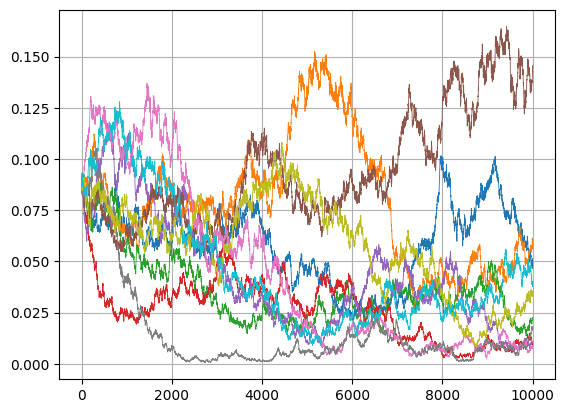

In [40]:
for i in range(N):
    plt.plot(gamma[i, :], linewidth = 0.6)

print(gamma[:, -1])
plt.grid() 
plt.show()